In [22]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)

import joblib

In [2]:
incident_df = pd.read_csv("/Users/raj/Desktop/CapStone/bankOps-platform/DataSets/incident_reports.csv")

In [3]:
display(incident_df.head())

,incident_id,timestamp,cpu_utilization,memory_usage,db_connection_pool_usage,network_throughput_mbps,application_error_rate,neft_success_rate,imps_success_rate,rtgs_success_rate,avg_transaction_processing_time_ms,incident_type,severity,is_critical
0,INC000001,2025-10-20 00:00:00,42.82,36.96,25.62,168.08,0,99.46,99.20,99.71,108.99,Normal,Low,0
1,INC000002,2025-10-20 01:00:00,38.23,39.58,33.64,215.29,2,96.62,98.36,99.86,100.11,Normal,Low,0
2,INC000003,2025-10-20 02:00:00,35.37,38.81,22.94,218.44,2,96.49,98.61,99.10,100.00,Normal,Low,0
3,INC000004,2025-10-20 03:00:00,36.81,37.07,39.59,185.52,3,98.56,99.96,99.60,100.00,Normal,Low,0
4,INC000005,2025-10-20 04:00:00,43.25,33.70,39.36,215.06,4,99.96,99.51,99.44,140.75,Normal,Low,0


In [7]:
incident_df.shape
incident_df.info()
incident_df.isnull().sum()
incident_df['is_critical'].value_counts()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 14 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   incident_id                         168 non-null    object 
 1   timestamp                           168 non-null    object 
 2   cpu_utilization                     168 non-null    float64
 3   memory_usage                        168 non-null    float64
 4   db_connection_pool_usage            168 non-null    float64
 5   network_throughput_mbps             168 non-null    float64
 6   application_error_rate              168 non-null    int64  
 7   neft_success_rate                   168 non-null    float64
 8   imps_success_rate                   168 non-null    float64
 9   rtgs_success_rate                   168 non-null    float64
 10  avg_transaction_processing_time_ms  168 non-null    float64
 11  incident_type                       168 non-n

is_critical
0    142
1     26
Name: count, dtype: int64

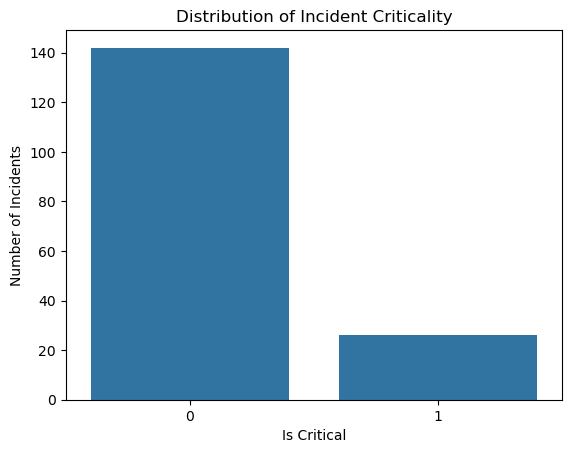

In [9]:
sns.countplot(data=incident_df, x='is_critical')

plt.title('Distribution of Incident Criticality')
plt.xlabel('Is Critical')
plt.ylabel('Number of Incidents')
plt.show()

Above plot shows that our data set is not a balanced data set.

In [10]:
features = [
    'cpu_utilization',
    'memory_usage',
    'db_connection_pool_usage',
    'network_throughput_mbps',
    'application_error_rate',
    'neft_success_rate',
    'imps_success_rate',
    'rtgs_success_rate',
    'avg_transaction_processing_time_ms'
]

X = incident_df[features]
y = incident_df['is_critical']

In [11]:
print("Independent variables shape:", X.shape)
print("Dependent variable shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Independent variables shape: (168, 9)
Dependent variable shape: (168,)

Target distribution:
is_critical
0    142
1     26
Name: count, dtype: int64


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [13]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42
)

In [14]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=2, min_samples_split=5,
                       random_state=42)

In [15]:
y_pred = rf_model.predict(X_test)

In [ ]:
y_pred_prob = rf_model.predict_proba(X_test)[:, 1]

In [21]:


rf_accuracy = accuracy_score(y_test, y_pred)

rf_precision = precision_score(y_test, y_pred, zero_division=0)

rf_recall = recall_score(y_test, y_pred, zero_division=0)

rf_f1 = f1_score(y_test, y_pred, zero_division=0)

rf_roc_auc = roc_auc_score(y_test, y_pred_prob)

print("Random Forest Performance")

print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)
print("ROC-AUC:", rf_roc_auc)


print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Random Forest Performance
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
ROC-AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        29
           1       1.00      1.00      1.00         5

    accuracy                           1.00        34
   macro avg       1.00      1.00      1.00        34
weighted avg       1.00      1.00      1.00        34



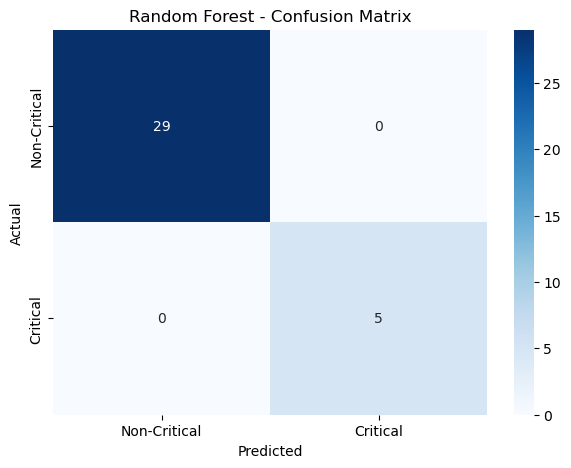

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Critical', 'Critical'],
    yticklabels=['Non-Critical', 'Critical']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [19]:
new_incident = pd.DataFrame({
    'cpu_utilization': [92.5],
    'memory_usage': [89.2],
    'db_connection_pool_usage': [95.0],
    'network_throughput_mbps': [180.0],
    'application_error_rate': [12.5],
    'neft_success_rate': [85.5],
    'imps_success_rate': [82.0],
    'rtgs_success_rate': [88.0],
    'avg_transaction_processing_time_ms': [850.0]
})

prediction = rf_model.predict(new_incident)

probability = rf_model.predict_proba(new_incident)[:, 1]

print("Predicted Criticality:", prediction[0])
print("Criticality Probability:", probability[0])

Predicted Criticality: 1
Criticality Probability: 0.9837417218543046


In [24]:
rf_artifact = {
    'model': rf_model,
    'features': features,
    'target': 'is_critical'
}

joblib.dump(rf_artifact, 'incident_criticality.pkl')

print("Incident Criticality Model Saved Successfully.")

Incident Criticality Model Saved Successfully.
